# 0_1 임베딩 사용 방법

- [Google 멀티모달 임베딩 안내](https://ai.google.dev/gemma/docs/embeddinggemma/multimodal-embeddinggemma-with-sentence-transformers)
- [EmbeddingGemma 2 모델 카드](https://huggingface.co/google/embeddinggemma-2)
- [FAISS 시작하기](https://github.com/facebookresearch/faiss/wiki/Getting-started)

**문장·사진을 숫자로 바꾸고, 가까운 사진을 찾아봅니다.**

- 입력: 텍스트 / 이미지 / 이미지 + 텍스트
- 출력: 768개 숫자로 이루어진 벡터 → 비슷한 이미지 3장

In [ ]:
# 관련 라이브러리 설치
# uv pip install faiss-cpu pillow "sentence-transformers[image]>=6.2" "transformers>=5.21"

# Windows에서도 이 실습의 FAISS 검색은 CPU를 사용합니다.
# GPU 검색은 WSL2/Linux 환경과 별도 설정이 필요합니다.
# GPU 검색과 인덱스 변환은 이 CPU 실습을 마친 뒤 별도로 다룹니다.


## 1. 모델 준비

`google/embeddinggemma-2`는 문장과 사진을 **같은 벡터 공간**으로 바꿉니다. 모델은 한 번만 불러옵니다.

CUDA → MPS → CPU 순서로 실행 장치를 고릅니다. 음성 인코더는 제외하고 `float32`를 사용합니다. 처음에는 모델 다운로드가 필요하며, 이후 추론은 내 컴퓨터에서 실행합니다.

In [1]:
# 1. 도구 준비: 파일 읽기와 모델·이미지·벡터 처리에 필요한 도구를 불러옵니다.
import json
import os
import sys
from pathlib import Path

# macOS에서는 두 라이브러리의 CPU 스레드 충돌을 피하도록 import 전에 설정합니다.
if sys.platform == "darwin":
    os.environ["OMP_NUM_THREADS"] = "1"

import faiss
import numpy as np
import torch
from IPython.display import display
from PIL import Image
from sentence_transformers import SentenceTransformer

# 2. 장치 선택: 사용할 수 있는 GPU가 없으면 CPU에서 모델을 실행합니다.
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

# 3. 모델 불러오기: 텍스트와 이미지를 처리할 모델을 선택한 장치에 올립니다.
model_id = "google/embeddinggemma-2"
model = SentenceTransformer(
    model_id,
    device=device,
    config_kwargs={"audio_config": None},
    model_kwargs={"torch_dtype": torch.float32},
)

# 4. 준비 확인: 불러온 모델과 실행 장치, 벡터의 숫자 개수를 확인합니다.
print("모델:", model_id)
print("모델 실행 장치:", device)
print("벡터 차원:", model.get_embedding_dimension())

모델: google/embeddinggemma-2
모델 실행 장치: mps
벡터 차원: 768


## 2. 테스트

`model.encode()`에 입력을 넣으면 숫자 배열이 나옵니다. `normalize_embeddings=True`는 벡터 길이를 1로 맞춥니다.

### 테스트 1 - 텍스트를 벡터로 만들기

**입력:** 검색 문장 → **출력:** `(768,)` 벡터 하나

`SearchQuery`는 모델에 들어 있는 검색용 지침입니다. 직접 만드는 프롬프트가 아닙니다.

In [2]:
# 1. 입력 준비: 찾고 싶은 사진을 문장으로 적습니다.
text = "딸기가 들어간 분홍색 모찌 사진"

# 2. 벡터 생성: 검색용 지침으로 문장을 숫자 배열로 바꾸고 길이를 1로 맞춥니다.
text_vector = model.encode(
    text,
    prompt_name="SearchQuery",
    normalize_embeddings=True,
)

# 3. 결과 확인: 입력 문장과 벡터 모양, 숫자 일부, 정규화된 길이를 확인합니다.
print("입력:", text)
print("벡터 모양:", text_vector.shape)
print("앞의 숫자 8개:", text_vector[:8])
print("벡터 길이:", round(float(np.linalg.norm(text_vector)), 4))

입력: 딸기가 들어간 분홍색 모찌 사진
벡터 모양: (768,)
앞의 숫자 8개: [-0.00104397 -0.00392118 -0.04486149 -0.00385467 -0.01301785  0.00319542
 -0.0436452   0.00800127]
벡터 길이: 1.0


### 테스트 2 - 이미지를 벡터로 만들기

**입력:** 딸기 모찌 사진 한 장 → **출력:** `(768,)` 벡터 하나

메뉴 대표 사진과 다른 장면의 합성 테스트 사진을 사용합니다. 사진은 화면에 보여주고, 파일 경로를 모델에 전달합니다.

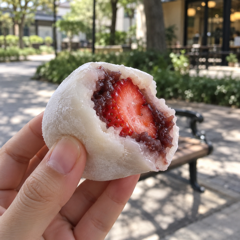

입력: search_strawberry_mochi_bitten.png
벡터 모양: (768,)
앞의 숫자 8개: [-0.0079687  -0.03849988 -0.05431998  0.01988897  0.00786456  0.03228218
 -0.0679308   0.01499518]
벡터 길이: 1.0


In [3]:
# 1. 입력 준비: 검색에 사용할 사진을 열어 어떤 이미지인지 확인합니다.
image_path = Path("../data/search_images/search_strawberry_mochi_bitten.png")
with Image.open(image_path) as image:
    display(image.convert("RGB").resize((240, 240)))

# 2. 벡터 생성: 사진 경로를 모델에 전달해 이미지 벡터 하나를 만듭니다.
image_vector = model.encode(
    {"image": str(image_path)},
    normalize_embeddings=True,
)

# 3. 결과 확인: 사진 이름과 벡터 모양, 숫자 일부, 정규화된 길이를 확인합니다.
print("입력:", image_path.name)
print("벡터 모양:", image_vector.shape)
print("앞의 숫자 8개:", image_vector[:8])
print("벡터 길이:", round(float(np.linalg.norm(image_vector)), 4))

### 테스트 3 - 이미지, 텍스트를 벡터로 만들기

**입력:** 사진 한 장 + 문장 하나 → **출력:** 둘을 함께 표현한 `(768,)` 벡터 하나

두 벡터를 더하는 방식이 아닙니다. 모델에 사진과 문장을 **함께** 넣습니다.

In [4]:
# 1. 입력 준비: 앞의 사진에 검색 문장을 붙여 하나의 입력으로 묶습니다.
combined_text = "이 사진처럼 딸기가 보이는 모찌"
combined_input = {"image": str(image_path), "text": combined_text}

# 2. 벡터 생성: 사진과 문장을 함께 모델에 넣어 벡터 하나를 만듭니다.
combined_vector = model.encode(
    combined_input,
    prompt_name="SearchQuery",
    normalize_embeddings=True,
)

# 3. 결과 확인: 두 입력이 벡터 하나로 바뀌었는지 모양과 숫자를 확인합니다.
print("입력:", combined_input)
print("벡터 모양:", combined_vector.shape)
print("앞의 숫자 8개:", combined_vector[:8])
print("벡터 길이:", round(float(np.linalg.norm(combined_vector)), 4))

입력: {'image': '../tests/fixtures/images/search/search_strawberry_mochi_bitten.png', 'text': '이 사진처럼 딸기가 보이는 모찌'}
벡터 모양: (768,)
앞의 숫자 8개: [ 0.00203876 -0.0279525  -0.07890277 -0.01142707  0.01123089  0.02489199
 -0.05879959  0.01498805]
벡터 길이: 1.0


## 3. 벡터 저장소 만들기

**FAISS**는 벡터를 모아 두고, 검색 벡터와 가까운 벡터를 찾는 라이브러리입니다. 여기서는 메뉴 사진의 벡터를 저장하고, 문장이나 사진으로 비슷한 메뉴를 찾는 데 사용합니다. 별도 데이터베이스 서버 없이 파일로 저장하고 다시 읽습니다.

### 이미지들 불러오기

`data/menu_images/`의 메뉴 사진을 읽습니다. **파일 목록의 순서 = 나중에 저장할 벡터의 순서**입니다.

저장할 이미지 수: 17
처음 3개: ['dessert_black_sesame_mochi.png', 'dessert_chestnut_mochi.png', 'dessert_injeolmi_mochi.png']


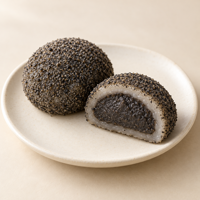

In [5]:
# 1. 사진 목록: 메뉴 사진 경로를 이름순으로 모아 벡터를 저장할 순서를 정합니다.
image_folder = Path("../data/menu_images")
image_paths = sorted(image_folder.glob("*.png"))

# 2. 목록 확인: 사진 개수와 파일 이름 일부를 보고 읽을 자료가 맞는지 확인합니다.
print("저장할 이미지 수:", len(image_paths))
print("처음 3개:", [path.name for path in image_paths[:3]])

# 3. 사진 확인: 목록의 첫 사진을 열어 저장할 이미지를 살펴봅니다.
with Image.open(image_paths[0]) as image:
    display(image.convert("RGB").resize((200, 200)))

### 저장하기

사진들을 벡터로 바꾼 뒤 FAISS 인덱스에 넣습니다.

정규화한 벡터에 `IndexFlatIP`를 사용하면 코사인 유사도로 비교할 수 있습니다. 검색은 CPU에서 실행합니다.

In [6]:
# 1. 벡터 생성: 파일 목록 순서대로 사진들을 모델에 넣어 정규화된 벡터를 만듭니다.
image_inputs = [{"image": str(path)} for path in image_paths]
image_vectors = model.encode(
    image_inputs,
    batch_size=2,
    normalize_embeddings=True,
    show_progress_bar=True,
)

# 2. 저장 형식: FAISS가 받을 수 있도록 벡터를 연속된 float32 배열로 맞춥니다.
image_vectors = np.ascontiguousarray(image_vectors, dtype="float32")

# 3. 저장소 생성: 벡터 차원에 맞는 검색 인덱스를 만들고 이미지 벡터를 넣습니다.
index = faiss.IndexFlatIP(image_vectors.shape[1])
index.add(image_vectors)

# 4. 저장 확인: 사진마다 벡터가 하나씩 들어갔는지 배열 모양과 저장 개수를 확인합니다.
print("이미지 벡터 모양:", image_vectors.shape)
print("저장소의 벡터 수:", index.ntotal)

이미지 벡터 모양: (17, 768)
저장소의 벡터 수: 17


벡터와 파일 목록을 **두 파일로 함께 저장**합니다. 다시 실행하면 이번 실습 파일만 덮어씁니다.

| 파일 | 담는 내용 |
|---|---|
| `images.faiss` | 이미지 벡터 |
| `images.json` | 모델 ID와 같은 순서의 이미지 경로 |

저장 위치는 `data/embeddings/practice_0_1/`입니다. 기존 실습 인덱스는 그대로 둡니다.

In [7]:
# 1. 경로 준비: 기존 인덱스와 구분할 실습 폴더와 두 저장 파일의 경로를 정합니다.
store_folder = Path("../data/embeddings/practice_0_1")
store_folder.mkdir(parents=True, exist_ok=True)
index_path = store_folder / "images.faiss"
metadata_path = store_folder / "images.json"

# 2. 벡터 저장: 검색에 사용할 이미지 벡터를 FAISS 파일로 저장합니다.
faiss.write_index(index, str(index_path))

# 3. 목록 저장: 벡터를 사진에 다시 연결할 수 있도록 모델 ID와 같은 순서의 경로를 저장합니다.
metadata = {
    "model_id": model_id,
    "image_paths": [str(path) for path in image_paths],
}
metadata_path.write_text(
    json.dumps(metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 4. 위치 확인: 만들어진 벡터 파일과 이미지 목록 파일의 위치를 확인합니다.
print("벡터 저장:", index_path)
print("파일 목록 저장:", metadata_path)

벡터 저장: ../data/embeddings/practice_0_1/images.faiss
파일 목록 저장: ../data/embeddings/practice_0_1/images.json


## 4. 검색 테스트

저장한 파일을 다시 읽습니다. **메뉴 사진은 다시 임베딩하지 않고**, 앞에서 만든 검색 벡터를 사용합니다.

In [8]:
# 1. 파일 읽기: 저장한 벡터와 이미지 경로 목록을 검색용 변수에 불러옵니다.
search_index = faiss.read_index(str(index_path))
stored_metadata = json.loads(metadata_path.read_text(encoding="utf-8"))
stored_image_paths = stored_metadata["image_paths"]

# 2. 자료 확인: 현재 모델과 벡터 차원, 파일 목록 개수가 저장 자료와 맞는지 확인합니다.
if stored_metadata["model_id"] != model_id:
    raise ValueError("저장할 때와 같은 모델을 사용하세요.")
if search_index.d != model.get_embedding_dimension():
    raise ValueError("현재 모델과 저장한 벡터의 차원이 다릅니다.")
if search_index.ntotal != len(stored_image_paths):
    raise ValueError("벡터 파일과 이미지 목록을 함께 다시 저장하세요.")

# 3. 준비 확인: 파일에서 읽은 벡터 개수와 차원을 확인합니다.
print("다시 읽은 벡터 수:", search_index.ntotal)
print("벡터 차원:", search_index.d)

다시 읽은 벡터 수: 17
벡터 차원: 768


검색 함수는 **벡터 하나 → 가까운 이미지 경로와 점수 목록**을 돌려줍니다. 표시 함수는 그 목록을 사진으로 보여줍니다.

In [9]:
def search_images(query_vector, top_k=3):
    """검색 벡터를 받아, 저장한 사진 중 가까운 이미지 경로와 유사도를 최대 top_k개 돌려줍니다."""
    # 1. 검색 준비: 벡터 하나를 FAISS가 받는 2차원 float32 배열로 바꿉니다.
    query = np.ascontiguousarray(query_vector.reshape(1, -1), dtype="float32")

    ## 배열로 바꾼 벡터와 가까운 사진 위치를 찾습니다.
    scores, positions = search_index.search(query, min(top_k, search_index.ntotal))

    # 2. 결과 연결: 검색 위치를 저장한 이미지 경로에 연결합니다.
    results = []
    for score, position in zip(scores[0], positions[0]):
        if position < 0:
            continue

        ## 유효한 검색 위치를 사진 경로와 점수로 묶습니다.
        results.append({
            "image_path": stored_image_paths[position],
            "score": float(score),
        })

    return results


def show_results(results):
    """검색 결과 목록을 받아, 가까운 순서대로 파일 이름·유사도·사진을 보여줍니다."""
    # 1. 후보 표시: 각 결과의 파일 이름과 점수를 출력하고 사진을 함께 보여줍니다.
    for result in results:
        path = Path(result["image_path"])
        print(f"{path.name} / 유사도 {result['score']:.4f}")

        ## 점수와 함께 비교할 수 있도록 후보 사진을 보여줍니다.
        with Image.open(path) as image:
            display(image.convert("RGB").resize((180, 180)))

### 테스트 1 - 텍스트로 검색하기

2절의 `text_vector`로 메뉴 사진을 찾습니다. **문장과 사진도 서로 비교**할 수 있습니다.

검색 문장: 딸기가 들어간 분홍색 모찌 사진
dessert_strawberry_mochi.png / 유사도 0.6982


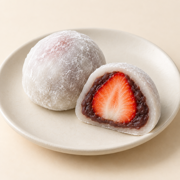

dessert_chestnut_mochi.png / 유사도 0.6154


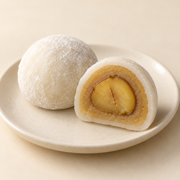

dessert_peanut_cream_mochi.png / 유사도 0.6104


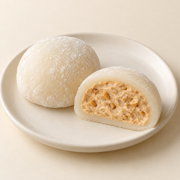

In [10]:
# 1. 입력 확인: 앞에서 벡터로 바꾼 검색 문장을 다시 확인합니다.
print("검색 문장:", text)

# 2. 사진 검색: 텍스트 벡터와 가까운 이미지 경로·점수를 받습니다.
text_results = search_images(text_vector)

# 3. 결과 확인: 검색된 사진을 유사도 순서대로 비교합니다.
show_results(text_results)

### 테스트 2 - 이미지로 검색하기

2절의 `image_vector`를 사용합니다. 입력 사진과 가까운 메뉴 사진을 비교해 보세요.

검색 이미지: search_strawberry_mochi_bitten.png


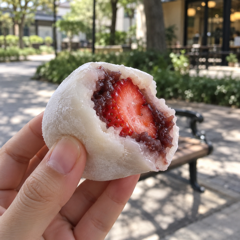

dessert_strawberry_mochi.png / 유사도 0.8855


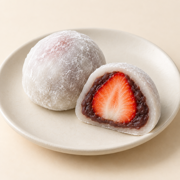

dessert_weekly_mochi.png / 유사도 0.8114


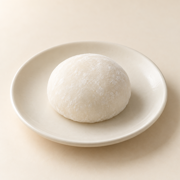

dessert_chestnut_mochi.png / 유사도 0.8084


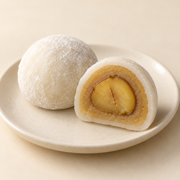

In [11]:
# 1. 입력 확인: 벡터로 바꾼 원본 사진을 다시 보여줍니다.
print("검색 이미지:", image_path.name)
with Image.open(image_path) as image:
    display(image.convert("RGB").resize((240, 240)))

# 2. 사진 검색: 이미지 벡터와 가까운 메뉴 사진을 찾습니다.
image_results = search_images(image_vector)

# 3. 결과 확인: 원본 사진과 검색 후보의 모습을 비교합니다.
show_results(image_results)

### 테스트 3 - 이미지, 텍스트로 검색하기

2절의 `combined_vector`를 사용합니다. 이미지 단독 검색과 후보 순서가 같은지 살펴보세요.

검색 이미지: search_strawberry_mochi_bitten.png
검색 문장: 이 사진처럼 딸기가 보이는 모찌
dessert_strawberry_mochi.png / 유사도 0.7807


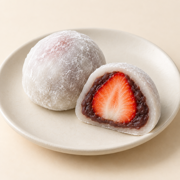

dessert_chestnut_mochi.png / 유사도 0.7305


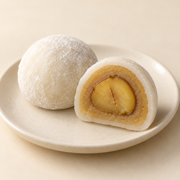

dessert_peanut_cream_mochi.png / 유사도 0.7218


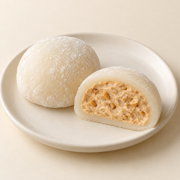

In [12]:
# 1. 입력 확인: 함께 벡터로 바꾼 사진 이름과 문장을 확인합니다.
print("검색 이미지:", image_path.name)
print("검색 문장:", combined_text)

# 2. 사진 검색: 사진과 문장을 함께 표현한 벡터로 가까운 메뉴 사진을 찾습니다.
combined_results = search_images(combined_vector)

# 3. 결과 확인: 이미지 단독 검색과 후보 순서가 어떻게 달라졌는지 비교합니다.
show_results(combined_results)